<center><h1>Лабораторная работа № 8</h1></center>

---

## **Тема:** <u>Предобработка изображений</u>.

**Цель работы** — познакомиться с основными операциями обработки изображений в библиотеке OpenCV: переводом в оттенки серого, бинаризацией, выравниванием гистограммы, фильтрацией шумов и морфологическими преобразованиями.



In [ ]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_DIR = Path("Lab8_images")
if not IMAGE_DIR.exists() and Path("../Lab8_images").exists():
    IMAGE_DIR = Path("../Lab8_images")


def load_photo(kind):
    user_candidates = [
        IMAGE_DIR / f"my_{kind}.jpg",
        IMAGE_DIR / f"my_{kind}.jpeg",
        IMAGE_DIR / f"my_{kind}.png",
    ]
    for path in user_candidates:
        if path.exists():
            image = cv2.imread(str(path), cv2.IMREAD_COLOR)
            if image is not None:
                return image, path.name, True

    demo_path = IMAGE_DIR / f"demo_{kind}.jpg"
    image = cv2.imread(str(demo_path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(
            f"Не удалось загрузить {demo_path}. Проверьте, что папка Lab8_images лежит рядом с ноутбуком."
        )
    return image, demo_path.name, False


def show_bgr(ax, image, title):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")


original_bgr, original_name, original_is_user = load_photo("original")
dark_bgr, dark_name, dark_is_user = load_photo("dark")
noisy_bgr, noisy_name, noisy_is_user = load_photo("noisy")
objects_bgr, objects_name, objects_is_user = load_photo("objects")

print("OpenCV version:", cv2.__version__)
print("Оригинальное изображение:", original_name, original_bgr.shape)
print("Затемнённое изображение:", dark_name, dark_bgr.shape)
print("Изображение с шумами:", noisy_name, noisy_bgr.shape)
print("Предметы на фоне:", objects_name, objects_bgr.shape)

OpenCV version: 5.0.0
Оригинальное изображение: demo_original.jpg (300, 451, 3)
Затемнённое изображение: my_dark.jpg (3768, 8160, 3)
Изображение с шумами: demo_noisy.jpg (300, 451, 3)
Предметы на фоне: demo_objects.jpg (480, 680, 3)


## 1. Исходное изображение, оттенки серого и два способа бинаризации


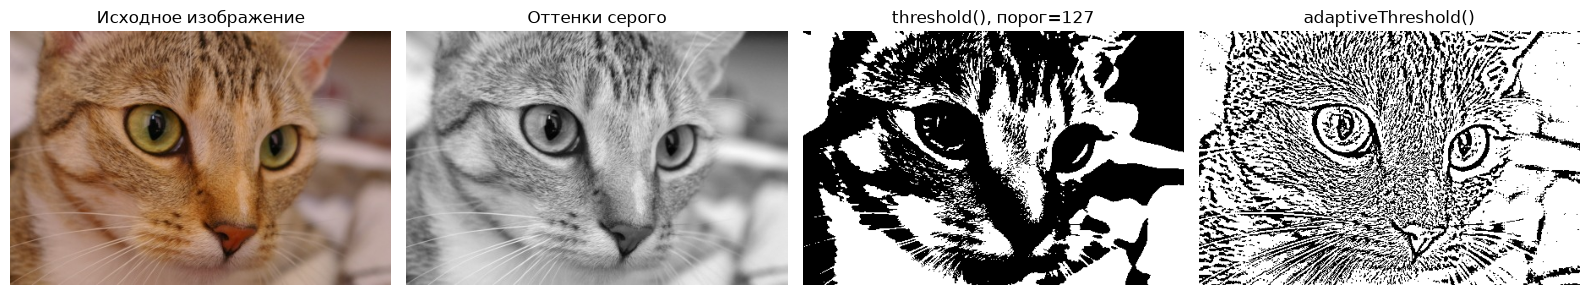

Размер цветного изображения: (300, 451, 3)
Размер изображения в оттенках серого: (300, 451)


In [ ]:
gray = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2GRAY)


threshold_value = 127
_, binary_threshold = cv2.threshold(
    gray,
    threshold_value,
    255,
    cv2.THRESH_BINARY
)

adaptive_binary = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,  
    2    
)

fig, axes = plt.subplots(1, 4, figsize=(16, 5))
show_bgr(axes[0], original_bgr, "Исходное изображение")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("Оттенки серого")
axes[1].axis("off")
axes[2].imshow(binary_threshold, cmap="gray")
axes[2].set_title(f"threshold(), порог={threshold_value}")
axes[2].axis("off")
axes[3].imshow(adaptive_binary, cmap="gray")
axes[3].set_title("adaptiveThreshold()")
axes[3].axis("off")
plt.tight_layout()
plt.show()

print("Размер цветного изображения:", original_bgr.shape)
print("Размер изображения в оттенках серого:", gray.shape)

## 2. Гистограмма затемнённого изображения и выравнивание освещённости


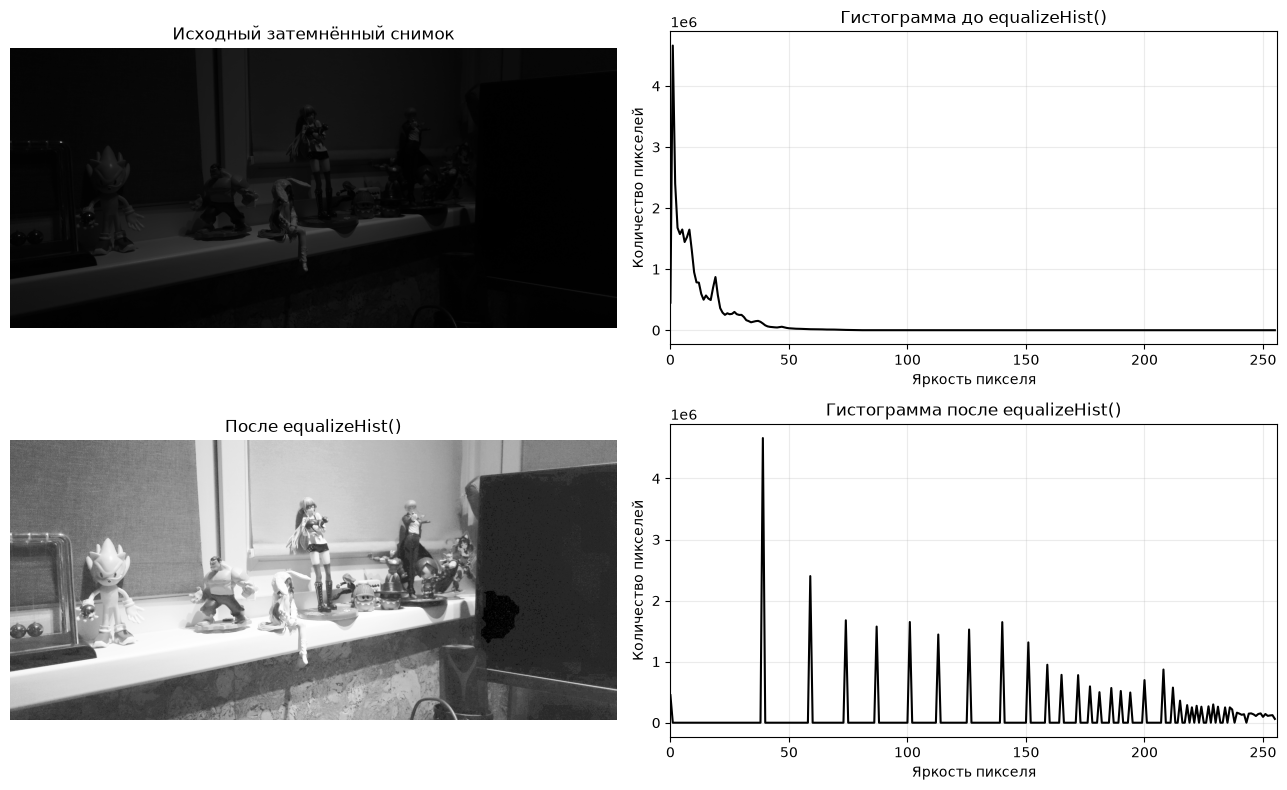

In [ ]:
dark_gray = cv2.cvtColor(dark_bgr, cv2.COLOR_BGR2GRAY)
equalized = cv2.equalizeHist(dark_gray)

hist_before = cv2.calcHist([dark_gray], [0], None, [256], [0, 256])
hist_after = cv2.calcHist([equalized], [0], None, [256], [0, 256])

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].imshow(dark_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Исходный затемнённый снимок")
axes[0, 0].axis("off")
axes[0, 1].plot(hist_before, color="black")
axes[0, 1].set_title("Гистограмма до equalizeHist()")
axes[0, 1].set_xlim([0, 256])
axes[0, 1].set_xlabel("Яркость пикселя")
axes[0, 1].set_ylabel("Количество пикселей")
axes[0, 1].grid(alpha=0.25)

axes[1, 0].imshow(equalized, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("После equalizeHist()")
axes[1, 0].axis("off")
axes[1, 1].plot(hist_after, color="black")
axes[1, 1].set_title("Гистограмма после equalizeHist()")
axes[1, 1].set_xlim([0, 256])
axes[1, 1].set_xlabel("Яркость пикселя")
axes[1, 1].set_ylabel("Количество пикселей")
axes[1, 1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 3. Фильтрация зашумлённого изображения

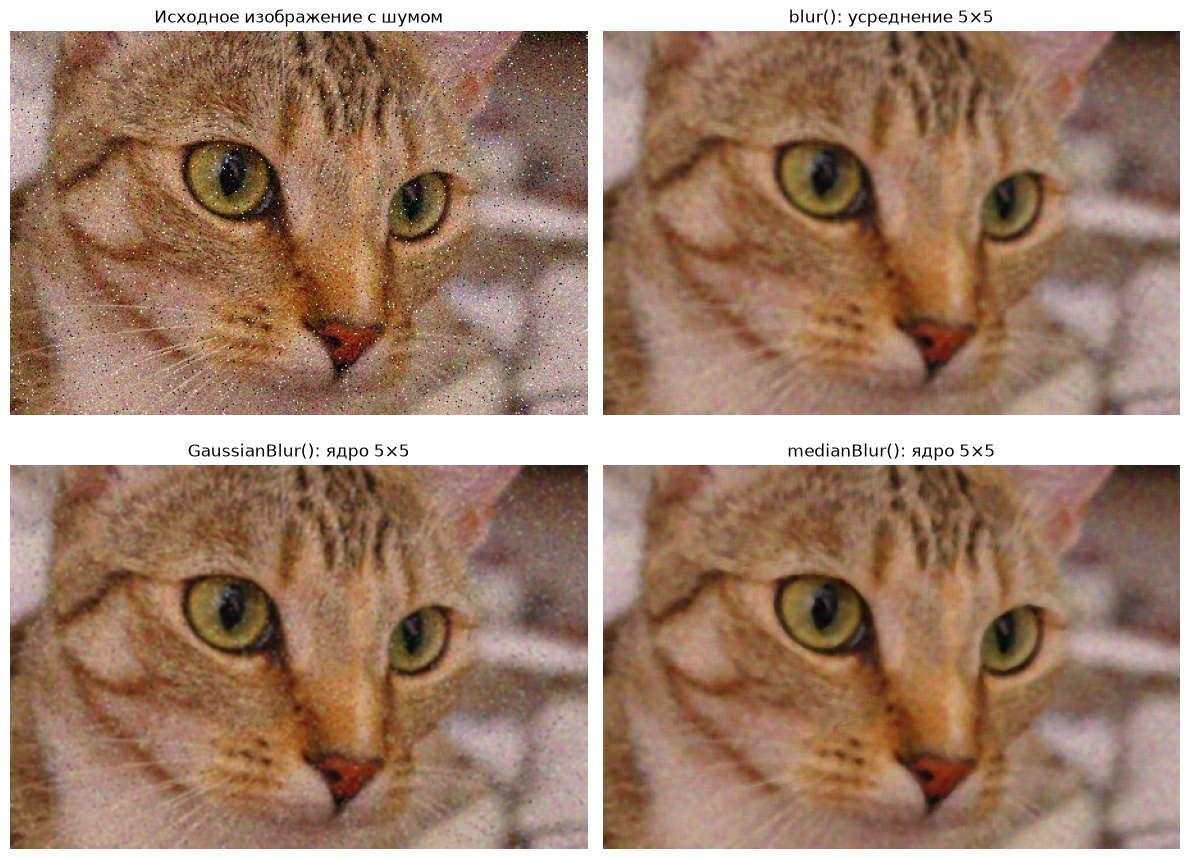

In [4]:
blurred = cv2.blur(noisy_bgr, (5, 5))
gaussian_blurred = cv2.GaussianBlur(noisy_bgr, (5, 5), sigmaX=0)
median_blurred = cv2.medianBlur(noisy_bgr, 5)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
show_bgr(axes[0, 0], noisy_bgr, "Исходное изображение с шумом")
show_bgr(axes[0, 1], blurred, "blur(): усреднение 5×5")
show_bgr(axes[1, 0], gaussian_blurred, "GaussianBlur(): ядро 5×5")
show_bgr(axes[1, 1], median_blurred, "medianBlur(): ядро 5×5")
plt.tight_layout()
plt.show()

## 4. Бинаризация, эрозия и дилатация


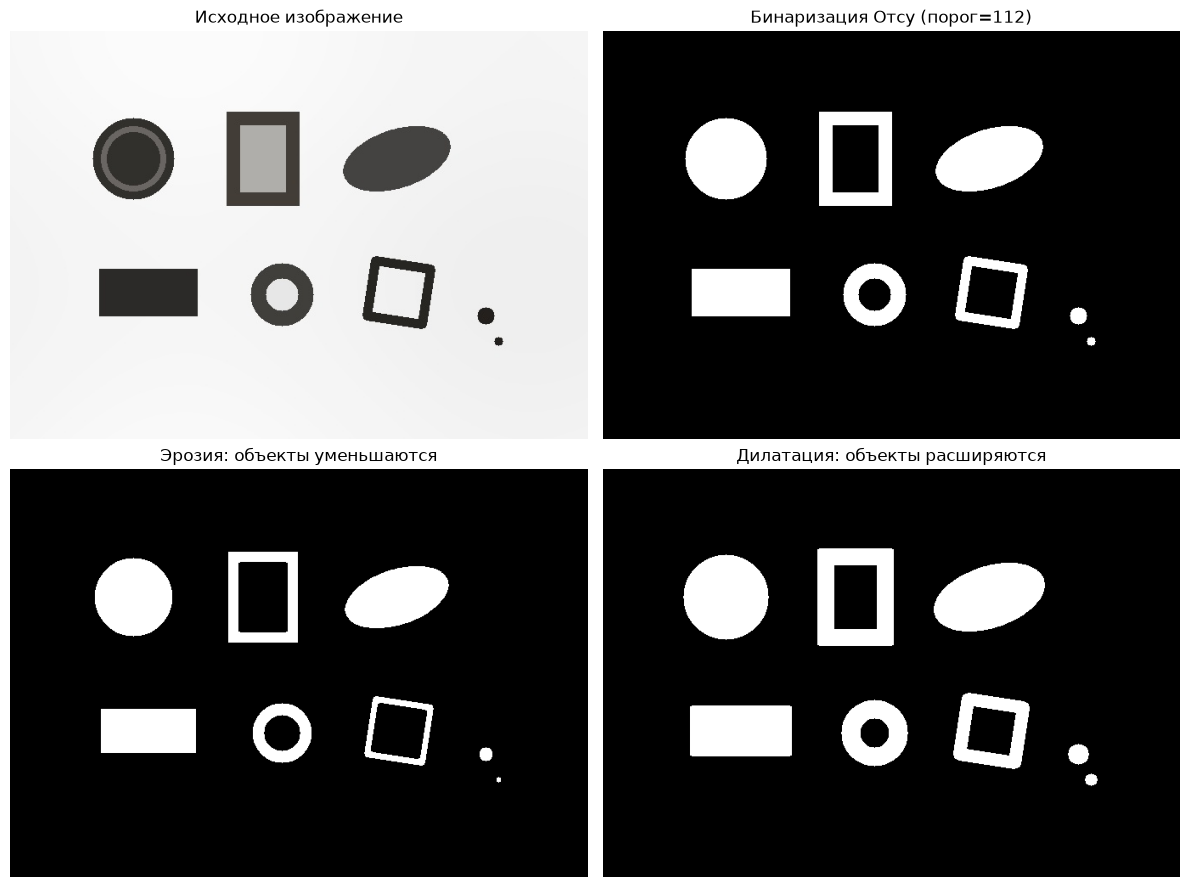

Площадь белого переднего плана после бинаризации: 32514 пикселей
После эрозии: 27336 пикселей
После дилатации: 37818 пикселей


In [ ]:
objects_gray = cv2.cvtColor(objects_bgr, cv2.COLOR_BGR2GRAY)

# Автоматический выбор порога методом Отсу; инверсия делает тёмные предметы белым передним планом.
otsu_threshold, objects_binary = cv2.threshold(
    objects_gray,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Эллиптическое ядро 5x5 применяется для эрозии и дилатации.
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
eroded = cv2.erode(objects_binary, kernel, iterations=1)
dilated = cv2.dilate(objects_binary, kernel, iterations=1)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
show_bgr(axes[0, 0], objects_bgr, "Исходное изображение")
axes[0, 1].imshow(objects_binary, cmap="gray")
axes[0, 1].set_title(f"Би                 наризация Отсу (порог={otsu_threshold:.0f})")
axes[0, 1].axis("off")
axes[1, 0].imshow(eroded, cmap="gray")
axes[1, 0].set_title("Эрозия: объекты уменьшаются")
axes[1, 0].axis("off")
axes[1, 1].imshow(dilated, cmap="gray")
axes[1, 1].set_title("Дилатация: объекты расширяются")
axes[1, 1].axis("off")
plt.tight_layout()
plt.show()

print("Площадь белого переднего плана после бинаризации:", cv2.countNonZero(objects_binary), "пикселей")
print("После эрозии:", cv2.countNonZero(eroded), "пикселей")
print("После дилатации:", cv2.countNonZero(dilated), "пикселей")

---
# Контрольные вопросы

### 1. Какой класс отвечает за работу с изображением?

В C++-интерфейсе OpenCV основной класс для представления изображения и матриц — `cv::Mat`. В Python изображения обычно представлены объектами `numpy.ndarray` (массивами NumPy), с которыми работают функции `cv2`. Например, `cv2.imread()` возвращает массив NumPy с пикселями изображения.

### 2. Какая функция конвертирует изображение в различные цветовые пространства?

Функция `cv2.cvtColor()`. Она преобразует изображение из одного цветового пространства в другое с помощью кода преобразования. Например, `cv2.COLOR_BGR2GRAY` переводит BGR-изображение в оттенки серого, а `cv2.COLOR_BGR2HSV` — в цветовое пространство HSV.

### 3. Что означает параметр `thresh` в функции бинаризации изображения?

`thresh` — это заданное пороговое значение яркости в `cv2.threshold(src, thresh, maxval, type)`. Для `THRESH_BINARY` пиксели со значением выше порога становятся равными `maxval`, остальные — 0. Для `THRESH_BINARY_INV` правило обратное. В OpenCV `cv2.threshold()` возвращает фактически применённый порог и бинарное изображение.

### 4. Как работает адаптивная бинаризация?

`cv2.adaptiveThreshold()` вычисляет порог отдельно для каждого пикселя на основании яркости его локальной окрестности. При `ADAPTIVE_THRESH_MEAN_C` используется локальное среднее, а при `ADAPTIVE_THRESH_GAUSSIAN_C` — взвешенное среднее с гауссовыми весами. `blockSize` задаёт размер окрестности и должен быть нечётным числом больше 1; `C` — константа, вычитаемая из локального значения. Этот подход полезен при неравномерном освещении.

### 5. Что такое гистограмма изображения и что можно сказать об изображении по его гистограмме?

Гистограмма показывает количество пикселей с каждым значением интенсивности. Для изображения в оттенках серого горизонтальная ось обычно содержит яркости от 0 до 255, а вертикальная — число пикселей с соответствующей яркостью. Скопление слева указывает на преобладание тёмных пикселей, справа — светлых. Узкий диапазон может говорить о низком контрасте, а более широкий — о распределении яркостей по большему диапазону. Гистограмма не показывает пространственное расположение пикселей.

### 6. Какими методами можно выровнять освещённость изображения?

Для повышения контраста можно использовать `cv2.equalizeHist()` для одноканального изображения в оттенках серого, CLAHE (`cv2.createCLAHE()`) для локального адаптивного выравнивания с ограничением контраста, линейную нормализацию (`cv2.normalize()`), растяжение контраста и гамма-коррекцию. Эти методы решают близкие, но не одинаковые задачи; простое выравнивание гистограммы не всегда устраняет сложную неравномерность освещения.

### 7. Расскажите принцип работы матричных фильтров. Что такое свёртка изображения?

Матричный фильтр использует небольшое ядро (матрицу коэффициентов), которое перемещается по изображению. Для каждого положения пиксели окрестности умножаются на коэффициенты ядра, результаты складываются и формируют новое значение центрального пикселя. Такая локальная операция обычно называется свёрткой изображения; в реализации `filter2D` OpenCV технически применяется корреляция ядром. Разные ядра могут размывать изображение, повышать резкость или выделять границы.

### 8. Расскажите принцип работы медианного фильтра. Чем результат медианного фильтра отличается от результата фильтра Гаусса?

Медианный фильтр заменяет каждый пиксель медианой значений в его окрестности. Он хорошо подавляет импульсный («соль и перец») шум и часто лучше сохраняет резкие границы. Гауссов фильтр вычисляет взвешенное среднее соседних пикселей, придавая центральным пикселям больший вес. Он эффективен для сглаживания многих типов высокочастотного шума, но обычно сильнее размывает края.

### 9. Назовите морфологические преобразования изображения.

Основные морфологические операции: эрозия (`erode`), дилатация (`dilate`), открытие (`morphologyEx` с `MORPH_OPEN`), закрытие (`MORPH_CLOSE`), морфологический градиент (`MORPH_GRADIENT`), top-hat (`MORPH_TOPHAT`) и black-hat (`MORPH_BLACKHAT`). Для выполнения операций задают структурирующий элемент — ядро определённой формы и размера.

### 10. Какой эффект наблюдается при применении морфологических операций к бинарному изображению?

Эрозия уменьшает белые области переднего плана и может удалить небольшие выступы. Дилатация расширяет белые области, может соединять близкие элементы и закрывать узкие разрывы. Открытие (эрозия, затем дилатация) помогает убрать мелкие белые шумовые объекты. Закрытие (дилатация, затем эрозия) помогает заполнять небольшие чёрные отверстия и разрывы. Градиент выделяет контуры объектов.

### 11. В каких ситуациях имеет смысл применять операции замыкания и размыкания?

**Размыкание (`MORPH_OPEN`)** применяют, когда нужно убрать небольшие светлые объекты или выступы переднего плана, сохранив более крупные объекты. **Замыкание (`MORPH_CLOSE`)** применяют, когда нужно заполнить маленькие тёмные отверстия, закрыть узкие разрывы или соединить близкие части объекта. Выбор зависит от того, какие области считаются передним планом и какого размера детали нужно удалить или сохранить.